# OmniXAS and New Data spectra

Compare FEFF spectrum counts, then view four shared OmniXAS material/site spectra with and without `xsedge+50` scaling.


In [1]:
from pathlib import Path
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Run from the repository root or tutorial_omnixas.
cwd = Path.cwd().resolve()
if (cwd / 'tutorial_omnixas').is_dir():
    REPO_ROOT = cwd
elif cwd.name == 'tutorial_omnixas' and (cwd.parent / 'tutorial_omnixas').is_dir():
    REPO_ROOT = cwd.parent
else:
    raise FileNotFoundError('Start Jupyter from the repository root or tutorial_omnixas.')

DATA_ROOT = Path(os.environ.get('OMNIXAS_DATA_ROOT', REPO_ROOT.parent / 'OmniXAS_data')).expanduser()
OMNIXAS_SPLIT_ROOT = REPO_ROOT / 'tutorial_omnixas' / 'material_id_and_site'
FIGSHARE_SPLIT_MANIFEST_PATH = DATA_ROOT / 'figshare_141_splits_unscaled' / 'manifest.csv'
FIGSHARE_RAW_MANIFEST_PATH = DATA_ROOT / 'figshare' / 'manifest.csv'
OMNIXAS_FEFF_ROOT = DATA_ROOT / 'materialscloud_omnixas_raw' / 'extracted' / 'FEFF'

for path in (OMNIXAS_SPLIT_ROOT, FIGSHARE_SPLIT_MANIFEST_PATH, FIGSHARE_RAW_MANIFEST_PATH, OMNIXAS_FEFF_ROOT):
    if not path.exists():
        raise FileNotFoundError(f'Missing data input: {path}. Set OMNIXAS_DATA_ROOT if needed.')


## Counts

Counts are site-specific FEFF spectra. New Data uses the 141-point split for Ti–Cu and the raw Figshare count for Zn.


,OmniXAS Data,New Data
Element,,
Ti,"6,422","3,226"
V,"10,813","3,514"
Cr,"3,067","1,265"
Mn,"17,052","4,933"
Fe,"12,067","4,881"
Co,"10,753","3,815"
Ni,"4,335","4,632"
Cu,"4,172","4,881"
Zn,0,"5,426"


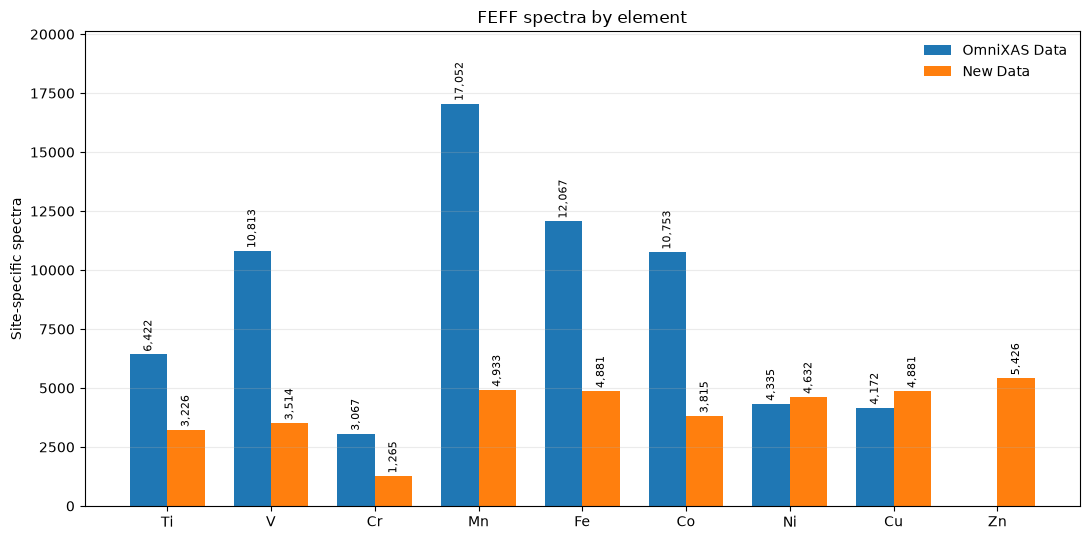

In [2]:
ELEMENTS_TO_COMPARE = ['Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn']
CORE_ELEMENTS = ELEMENTS_TO_COMPARE[:-1]

# Count the published OmniXAS FEFF split IDs.
omnixas_counts = {}
for element in CORE_ELEMENTS:
    split_paths = [OMNIXAS_SPLIT_ROOT / f'{element}_FEFF_{split}.txt' for split in ('train', 'val', 'test')]
    missing = [path for path in split_paths if not path.is_file()]
    if missing:
        raise FileNotFoundError(f'Missing OmniXAS split file(s): {missing}')
    omnixas_counts[element] = sum(1 for path in split_paths for line in path.read_text(encoding='utf-8').splitlines() if line.strip())

figshare_split = pd.read_csv(FIGSHARE_SPLIT_MANIFEST_PATH, dtype={'element': str, 'material_id': str})
figshare_raw = pd.read_csv(FIGSHARE_RAW_MANIFEST_PATH, dtype={'element': str})
if 'element' not in figshare_split.columns or 'element' not in figshare_raw.columns:
    raise ValueError('Figshare manifests must contain an element column.')
figshare_split_counts = figshare_split.groupby('element').size()
figshare_raw_counts = figshare_raw.groupby('element').size()

new_data_counts = figshare_split_counts.reindex(CORE_ELEMENTS, fill_value=0).reindex(ELEMENTS_TO_COMPARE, fill_value=0)
new_data_counts.loc['Zn'] = int(figshare_raw_counts.get('Zn', 0))
count_table = pd.DataFrame({
    'OmniXAS Data': pd.Series(omnixas_counts).reindex(ELEMENTS_TO_COMPARE, fill_value=0),
    'New Data': new_data_counts,
}).rename_axis('Element')
display(count_table.style.format('{:,}'))

# Build material/site keys for selecting shared examples.
figshare_manifest = figshare_raw.copy()
figshare_manifest['site'] = pd.to_numeric(figshare_manifest['site'], errors='raise').astype(int)
omnixas_key_rows = []
for element in CORE_ELEMENTS:
    for split in ('train', 'val', 'test'):
        path = OMNIXAS_SPLIT_ROOT / f'{element}_FEFF_{split}.txt'
        for record in path.read_text(encoding='utf-8').splitlines():
            record = record.strip()
            if record:
                match = re.fullmatch(r'(.+)_([0-9]+)', record)
                if not match:
                    raise ValueError(f'Unexpected material/site ID in {path}: {record}')
                omnixas_key_rows.append((element, match.group(1), int(match.group(2))))
omnixas_keys = pd.DataFrame(omnixas_key_rows, columns=['element', 'material_id', 'site'])

x = np.arange(len(count_table))
width = 0.36
fig, ax = plt.subplots(figsize=(11, 5.5))
bars_omnixas = ax.bar(x - width / 2, count_table['OmniXAS Data'], width, label='OmniXAS Data')
bars_new = ax.bar(x + width / 2, count_table['New Data'], width, label='New Data')
ax.set_title('FEFF spectra by element')
ax.set_ylabel('Site-specific spectra')
ax.set_xticks(x, count_table.index)
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.25)
for bars in (bars_omnixas, bars_new):
    ax.bar_label(bars, labels=[f'{int(bar.get_height()):,}' if bar.get_height() else '' for bar in bars], padding=2, fontsize=8, rotation=90)
ax.margins(y=0.18)
fig.tight_layout()
plt.show()


## Four shared FEFF examples

Figshare confirms that each material/site is present. Both curves come from OmniXAS FEFF output; one is unscaled and one uses `xsedge+50`. The window is 0–35 eV above the element K-edge start.


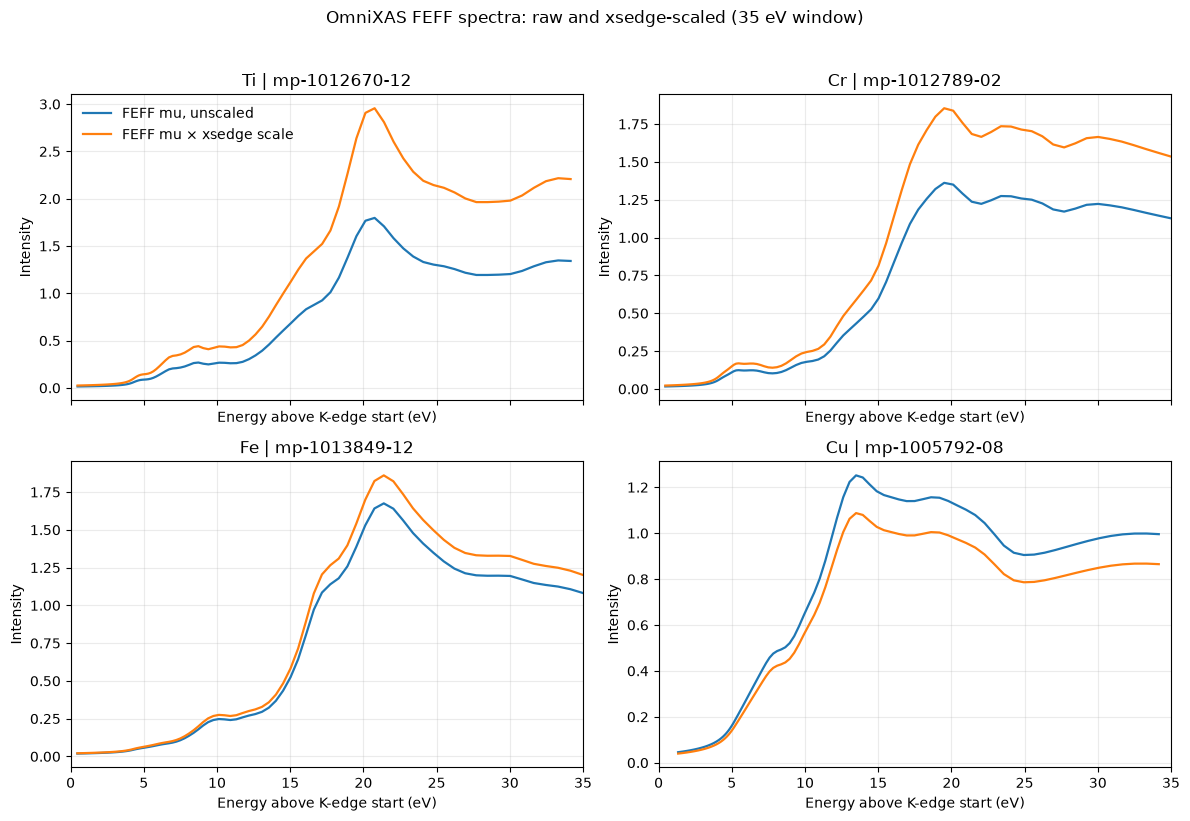

Selected shared examples:


,element,material_id,absorber_site,xsedge+50,scale_factor,spectrum_source
0,Ti,mp-1012670,12,0.000461,1.645082,/home/ayanaky/OmniXAS_data/materialscloud_omni...
1,Cr,mp-1012789,2,0.000381,1.361861,/home/ayanaky/OmniXAS_data/materialscloud_omni...
2,Fe,mp-1013849,12,0.000311,1.110673,/home/ayanaky/OmniXAS_data/materialscloud_omni...
3,Cu,mp-1005792,8,0.000243,0.868733,/home/ayanaky/OmniXAS_data/materialscloud_omni...


In [3]:
# The same material and absorbing site must occur in both inventories. Figshare identifies overlap; curves come from OmniXAS_FEFF_ROOT.
omnixas_key_set = set(zip(omnixas_keys['element'], omnixas_keys['material_id'], omnixas_keys['site']))
figshare_key_set = set(zip(figshare_manifest['element'], figshare_manifest['material_id'], figshare_manifest['site']))
common_keys = omnixas_key_set & figshare_key_set

EXAMPLE_ELEMENTS = ['Ti', 'Cr', 'Fe', 'Cu']
EDGE_START_EV = {'Ti': 4964.504, 'Cr': 5989.168, 'Fe': 7111.230, 'Cu': 8983.173}
WINDOW_EV = 35.0
BOHR_RADIUS_ANGSTROM = 0.529177210903
XS_EDGE_PATTERN = re.compile(r'xsedge\s*\+\s*50.*?([+-]?(?:\d+\.?\d*|\.\d+)(?:[Ee][+-]?\d+)?)', re.IGNORECASE)

def find_xsedge_plus_50(path):
    for line in path.read_text(encoding='utf-8', errors='replace').splitlines():
        if 'xsedge' not in line.lower():
            continue
        match = XS_EDGE_PATTERN.search(line)
        if match:
            return float(match.group(1))
    raise ValueError(f'No xsedge+50 value found in xmu header: {path}')

def omnixas_xmu_path(element, material_id, site):
    return (OMNIXAS_FEFF_ROOT / element / material_id / 'FEFF-XANES' / f'{site:03d}_{element}' / 'xmu.dat')

selected = []
for element in EXAMPLE_ELEMENTS:
    candidates = sorted((material_id, site) for el, material_id, site in common_keys if el == element)
    for material_id, site in candidates:
        path = omnixas_xmu_path(element, material_id, site)
        if path.is_file():
            selected.append((element, material_id, site, path))
            break
    else:
        raise FileNotFoundError(f'No overlapping {element} material/site with an OmniXAS xmu.dat was found under {OMNIXAS_FEFF_ROOT}')

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
selection_rows = []
for ax, (element, material_id, site, path) in zip(axes.flat, selected):
    table = np.loadtxt(path, comments='#', dtype=np.float64, ndmin=2)
    if table.shape[1] < 4 or not np.isfinite(table[:, [0, 3]]).all():
        raise ValueError(f'Expected finite energy and mu columns in {path}; got {table.shape}')
    xsedge_plus_50 = find_xsedge_plus_50(path)
    scale = xsedge_plus_50 / (BOHR_RADIUS_ANGSTROM ** 2) * 1000.0
    energy_above_edge = table[:, 0] - EDGE_START_EV[element]
    mu = table[:, 3]
    mask = (energy_above_edge >= 0) & (energy_above_edge <= WINDOW_EV) & np.isfinite(mu)
    if not mask.any():
        raise ValueError(f'No rows in the 0-35 eV window for {path}')
    ax.plot(energy_above_edge[mask], mu[mask], label='FEFF mu, unscaled', linewidth=1.6)
    ax.plot(energy_above_edge[mask], mu[mask] * scale, label='FEFF mu × xsedge scale', linewidth=1.6)
    ax.set_title(f'{element} | {material_id}-{site:02d}')
    ax.set_xlim(0, WINDOW_EV)
    ax.set_xlabel('Energy above K-edge start (eV)')
    ax.set_ylabel('Intensity')
    ax.grid(alpha=0.25)
    selection_rows.append({
        'element': element, 'material_id': material_id, 'absorber_site': site,
        'xsedge+50': xsedge_plus_50, 'scale_factor': scale,
        'spectrum_source': str(path),
    })
axes.flat[0].legend(frameon=False)
fig.suptitle('OmniXAS FEFF spectra: raw and xsedge-scaled (35 eV window)', y=1.02)
fig.tight_layout()
plt.show()

print('Selected shared examples:')
display(pd.DataFrame(selection_rows))